# Optimal control with pyadjoint

[pyadjoint](https://pyadjoint.org) (Mitusch, Funke, Dokken; the engine of dolfin-adjoint and
of `firedrake.adjoint`) records a computation on a tape and derives the adjoint model
from it.  `ngsufl.pyadjoint` connects it to ngsufl: the adjoint equations are formed in
UFL with `derivative`, `adjoint` and `action`, and assembled and solved by NGSolve.
It needs one more package:

```bash
pip install pyadjoint-ad
```

This part of ngsufl is a prototype: first derivatives with respect to functions and
constants are there, the limits are listed at the end.

## The problem

The "mother problem" of PDE constrained optimisation, after the
[dolfin-adjoint documentation](https://www.dolfin-adjoint.org/en/latest/documentation/poisson-mother/poisson-mother.html):
find the source $f$ such that the solution $u$ of the Poisson problem is close to a
given $d$,

$$ \min_f \; \frac12 \int_\Omega (u - d)^2 \, dx + \frac{\alpha}{2} \int_\Omega f^2 \, dx
   \qquad \text{subject to} \qquad -\Delta u = f \ \text{in } \Omega = (0,1)^2, \quad u = 0 \ \text{on } \partial\Omega . $$

With $w = \sin \pi x \sin \pi y$ and $d = w / (2\pi^2)$ the solution is known,

$$ f = \frac{w}{1 + 4 \alpha \pi^4}, \qquad u = \frac{f}{2 \pi^2} . $$

In [1]:
from ngsufl import *
from ngsufl.pyadjoint import *

mesh = UnitSquareMesh(32, 32)
V = FunctionSpace(mesh, "CG", 1)
W = FunctionSpace(mesh, "DG", 0)

x, y = SpatialCoordinate(mesh)
w = sin(pi * x) * sin(pi * y)
d = w / (2 * pi**2)
alpha = 1e-6

## The forward model, recorded

After `continue_annotation()` every `solve`, `project`, `assign` and every assembled
functional goes onto the tape.  The model itself is ordinary ngsufl code.

In [2]:
continue_annotation()

f = Function(W, name="control")
u = Function(V, name="state")
trial, v = TrialFunction(V), TestFunction(V)

solve(inner(grad(trial), grad(v)) * dx == f * v * dx, u, bcs=DirichletBC(V, 0, "on_boundary"))

J = assemble(0.5 * (u - d)**2 * dx + alpha / 2 * f**2 * dx)
print("J(0) =", float(J))

J(0) = 0.00032081194545887943


## The reduced functional and its gradient

`ReducedFunctional` is the map $f \mapsto J$.  Evaluating it replays the tape, and its
derivative runs the adjoint model: one transposed solve per recorded solve.

The Taylor test checks the gradient: the remainder $|J(f + \epsilon h) - J(f) - \epsilon\, dJ(h)|$
has to decay like $\epsilon^2$.

In [3]:
Jhat = ReducedFunctional(J, Control(f, riesz_map="l2"))

h = Function(W).interpolate(sin(3 * x) * cos(2 * y))
rate = taylor_test(Jhat, f, h)

Running Taylor test
Computed residuals: [1.4355949016884331e-08, 3.588987254867369e-09, 8.972468143449172e-10, 2.243117041171072e-10]
Computed convergence rates: [np.float64(1.999999999740207), np.float64(1.9999999989901098), np.float64(1.9999999965855775)]


The derivative is a linear functional on the control space.  As a function it is shown
through a Riesz map, by default the $L^2$ one.  At $f = 0$ the $L^2$ gradient is the
adjoint state $\lambda$ with $-\Delta \lambda = u - d = -d$, a negative bump.

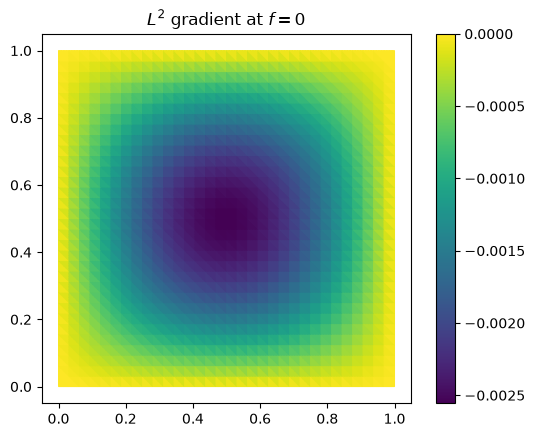

In [4]:
import matplotlib.pyplot as plt
from ngsufl.pyplot import tripcolor

Jhat_L2 = ReducedFunctional(J, Control(f))
Jhat_L2(f)
gradient = Jhat_L2.derivative(apply_riesz=True)

fig, axes = plt.subplots()
colors = tripcolor(gradient, axes=axes)
fig.colorbar(colors)
axes.set_title("$L^2$ gradient at $f = 0$")
axes.set_aspect("equal");

## Optimisation

`minimize` hands the reduced functional to SciPy.  SciPy works on the coefficient
vector, which is why the control above was created with `riesz_map="l2"`.

In [5]:
f_opt = minimize(Jhat, method="L-BFGS-B", tol=1e-13, options={"maxiter": 500, "gtol": 1e-13, "ftol": 1e-16})
pause_annotation()

u_opt = Function(V)
solve(inner(grad(trial), grad(v)) * dx == f_opt * v * dx, u_opt, bcs=DirichletBC(V, 0, "on_boundary"))

f_exact = w / (1 + 4 * alpha * pi**4)
u_exact = f_exact / (2 * pi**2)
print("J at the optimum  :", Jhat(f_opt))
print("error in f (L2)   :", errornorm(f_exact, f_opt))
print("error in u (L2)   :", errornorm(u_exact, u_opt))

J at the optimum  : 1.2594152845926326e-07
error in f (L2)   : 0.017105573270653575
error in u (L2)   : 2.188305205612893e-05


The control is piecewise constant, so its error is of first order in the mesh size;
the state error is of second order.

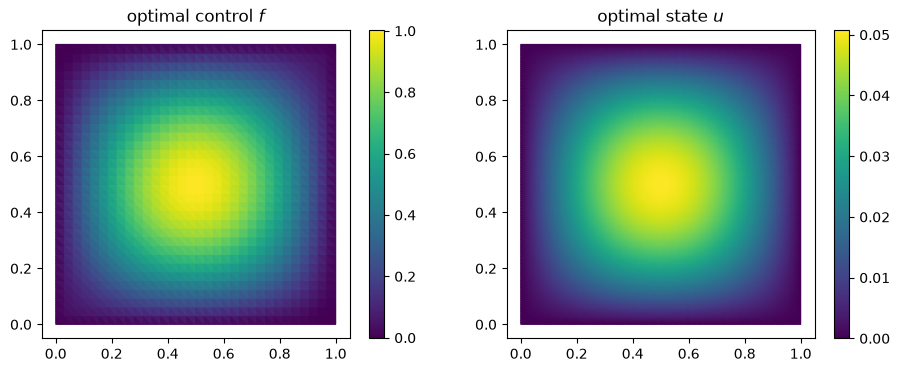

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, fn, title in zip(axes, (f_opt, u_opt), ("optimal control $f$", "optimal state $u$")):
    colors = tripcolor(fn, axes=ax)
    fig.colorbar(colors, ax=ax)
    ax.set_title(title)
    ax.set_aspect("equal");

## A nonlinear problem with a parameter

Derivatives with respect to a `Constant` work the same way.  Here the diffusion
coefficient is $1 + u^2$ and the parameter $k$ scales the reaction term.  The adjoint
derivative is compared with a difference quotient.

In [7]:
set_working_tape(Tape())
continue_annotation()

k = Constant(2.0)
u = Function(V)
F = (1 + u**2) * inner(grad(u), grad(v)) * dx + k * u * v * dx - 10 * x * v * dx
solve(F == 0, u, bcs=DirichletBC(V, 0, (1, 3)))
J = assemble(u**2 * dx)

dJdk = ReducedFunctional(J, Control(k)).derivative()
pause_annotation()


def J_of(value):
    k.assign(value)
    solve(F == 0, u, bcs=DirichletBC(V, 0, (1, 3)))
    return assemble(u**2 * dx)


eps = 1e-5
print("adjoint            :", float(dJdk.values()[0]))
print("difference quotient:", (J_of(2 + eps) - J_of(2 - eps)) / (2 * eps))

adjoint            : -0.0763054442717887
difference quotient: -0.07630547787240705


## What is covered

* controls: `Function` and `Constant`, several at once;
* recorded: `solve` for linear and nonlinear problems, the variational solver classes,
  `project`, `assemble` of functionals, `Function.assign` with functions and linear
  combinations, `copy`, `+=`;
* time loops, mixed problems (with `split(u)` in the forms);
* `ReducedFunctional`, `taylor_test`, `minimize`, `compute_gradient` of pyadjoint.

Not available yet: second derivatives (Hessian actions), Dirichlet values as controls,
components of mixed functions (`u.subfunctions`) on the tape, and therefore the
Irksome steppers, the assembled route `solve(A, x, b)`, and shape derivatives.
Unsupported operations raise an error.

Bound constraints of SciPy act on the coefficients.  They are bounds on the function
values for degree 0 and degree 1 controls only.